# R les 4 - Eurostat

In [ ]:
install.packages("tidyverse")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
install.packages("eurostat")

Installing package into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)



In [ ]:
library(tidyverse)

In [ ]:
library(eurostat)

## Inlezen data

In [ ]:
accidents_data <- search_eurostat("accidents")

In [ ]:
accidents_data

title,code,type,last.update.of.data,last.table.structure.change,data.start,data.end,values,hierarchy
<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<chr>,<dbl>,<dbl>
Victims in road accidents by NUTS 2 region,tran_r_acci,dataset,25.03.2026,04.03.2026,1990,2024,56303,5
Persons killed in road accidents - ENP-South countries,enps_tran_sf_r,dataset,05.03.2026,05.03.2026,2005,2025,170,6
Road accidents: persons killed,med_rd7,dataset,28.05.2020,10.01.2024,2005,2018,109,6
Deaths related to transport accidents occurring in the country,hlth_cd_tro,dataset,14.04.2026,10.11.2025,2011,2024,19045,5
Detailed deaths related to transport accidents occurring in the EU,hlth_cd_troeu,dataset,13.03.2026,13.03.2026,2011,2023,6230,5
"Accidents at work of employees by sex and age, excluding road traffic accidents and accidents on board of any mean of transport in the course of work (NACE Rev. 2 activity A, C-N excluding H)",hsw_mi03,dataset,26.03.2026,14.10.2025,2008,2023,136346,6
Non-fatal accidents at work by NACE Rev. 2 activity and sex,hsw_n2_01,dataset,16.04.2026,26.06.2025,2008,2023,425450,6
Non-fatal accidents at work by NACE Rev. 2 activity and age,hsw_n2_03,dataset,16.04.2026,26.06.2025,2008,2023,1270037,6
"Number of accidents at work by contact - mode of injury, NACE Rev. 1.1 activity, sex, age and severity",hsw_aw_co1,dataset,27.03.2009,03.01.2024,2005,2005,498,6


In [ ]:
data <- get_eurostat("tran_r_acci")

Dataset query already saved in cache_list.json...

Reading cache file /tmp/RtmpzjIjg0/eurostat/fd7a0ea3ce15a99f673d18cc89e64af5.rds

Table  tran_r_acci  read from cache file:  /tmp/RtmpzjIjg0/eurostat/fd7a0ea3ce15a99f673d18cc89e64af5.rds



In [ ]:
head(data)

freq,victim,unit,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<date>,<dbl>
A,INJ,NR,AL,2017-01-01,2389
A,INJ,NR,AL,2018-01-01,2078
A,INJ,NR,AL,2019-01-01,1817
A,INJ,NR,AL,2020-01-01,1417
A,INJ,NR,AL,2021-01-01,1663
A,INJ,NR,AL,2022-01-01,1435


In [ ]:
colnames(data)

[1] "freq"        "victim"      "unit"        "geo"         "TIME_PERIOD"
[6] "values"

Here is an explanation of the typical column names you might find in Eurostat datasets, specifically for accident statistics like 'Victims in road accidents by NUTS 2 region':

*   **`geo`**: Refers to the geographical unit. For this dataset, it will likely represent NUTS 2 regions or countries.
*   **`time`**: Indicates the time period for the data, typically years.
*   **`values`**: Contains the actual statistical values, which in this case would be the number of victims in road accidents.
*   **`unit`**: The unit of measurement for the `values` column (e.g., 'number', 'per 100 000 inhabitants').
*   **`sex`**: (If present) The gender of the victims (e.g., 'Total', 'Males', 'Females').
*   **`age`**: (If present) The age group of the victims.
*   **`indic_vi`**: (If present) The indicator of victims (e.g., 'killed', 'injured').

The specific columns present in your `data` variable can be confirmed by looking at the output of `colnames(data)`.

## Mooie grafiek

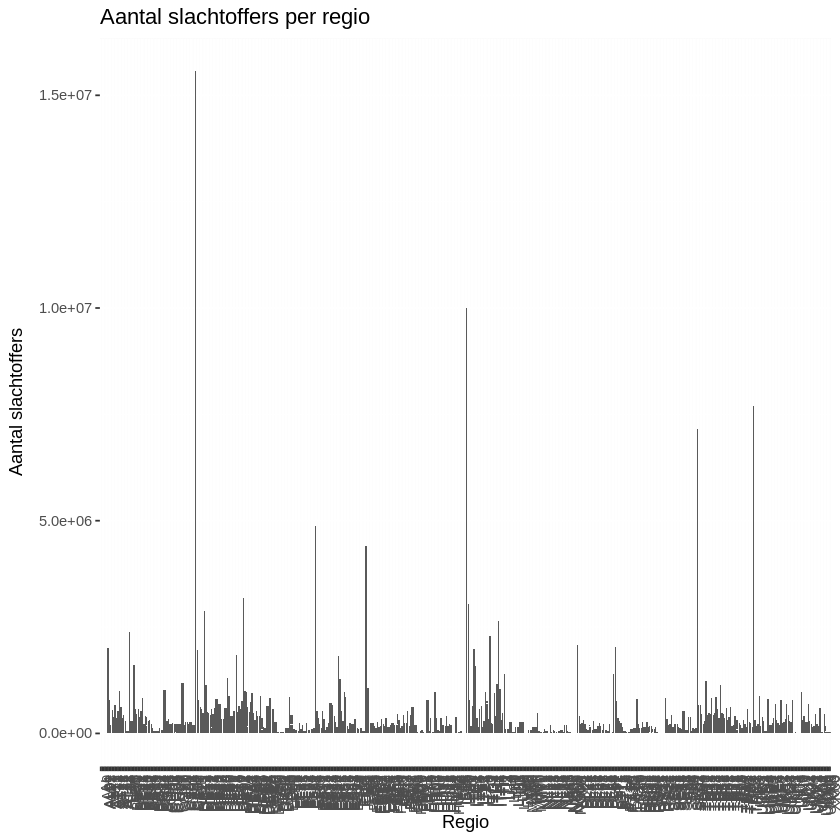

In [ ]:
data %>%
  drop_na(geo, values) %>%
  ggplot(aes(x = geo, y = values)) +
  geom_col() +
  labs(title = "Aantal slachtoffers per regio", x = "Regio", y = "Aantal slachtoffers") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1))

### Nog mooiere grafiek

In [ ]:
new_data <- data %>%
  filter(geo %in% c("AT32", "AT33"))

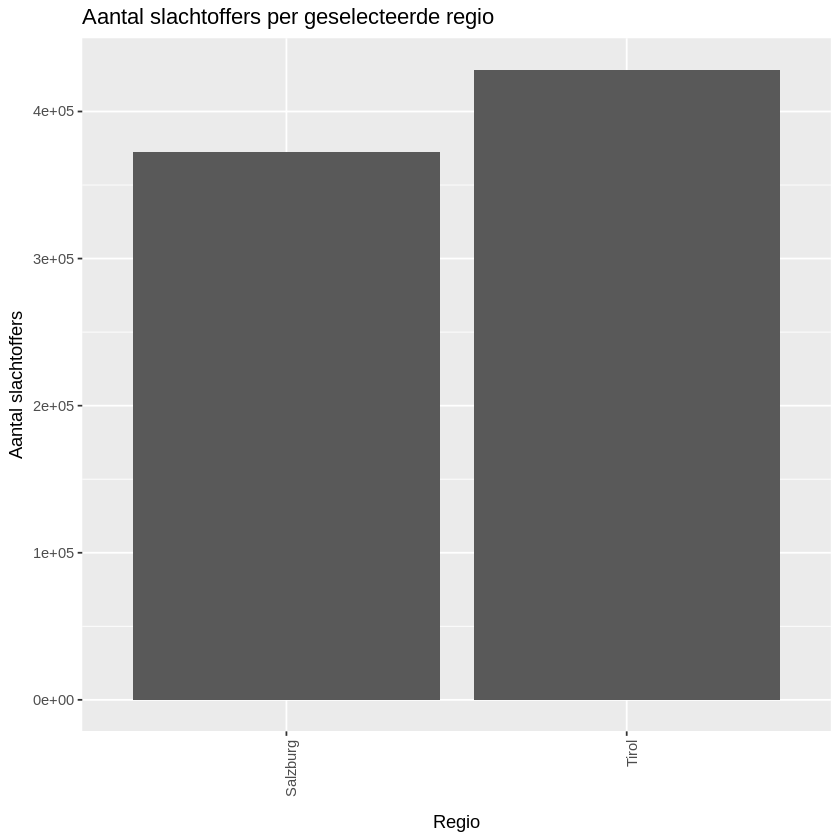

In [ ]:
new_data_labeled <- label_eurostat(new_data, "geo")

new_data_labeled %>%
  drop_na(geo, values) %>%
  ggplot(aes(x = geo, y = values)) +
  geom_col() +
  labs(title = "Aantal slachtoffers per geselecteerde regio", x = "Regio", y = "Aantal slachtoffers") +
  theme(axis.text.x = element_text(angle = 90, hjust = 1))

`summarise()` has regrouped the output.
ℹ Summaries were computed grouped by Year and geo.
ℹ Output is grouped by Year.
ℹ Use `summarise(.groups = "drop_last")` to silence this message.
ℹ Use `summarise(.by = c(Year, geo))` for per-operation grouping
  (`?dplyr::dplyr_by`) instead.
`geom_smooth()` using formula = 'y ~ x'


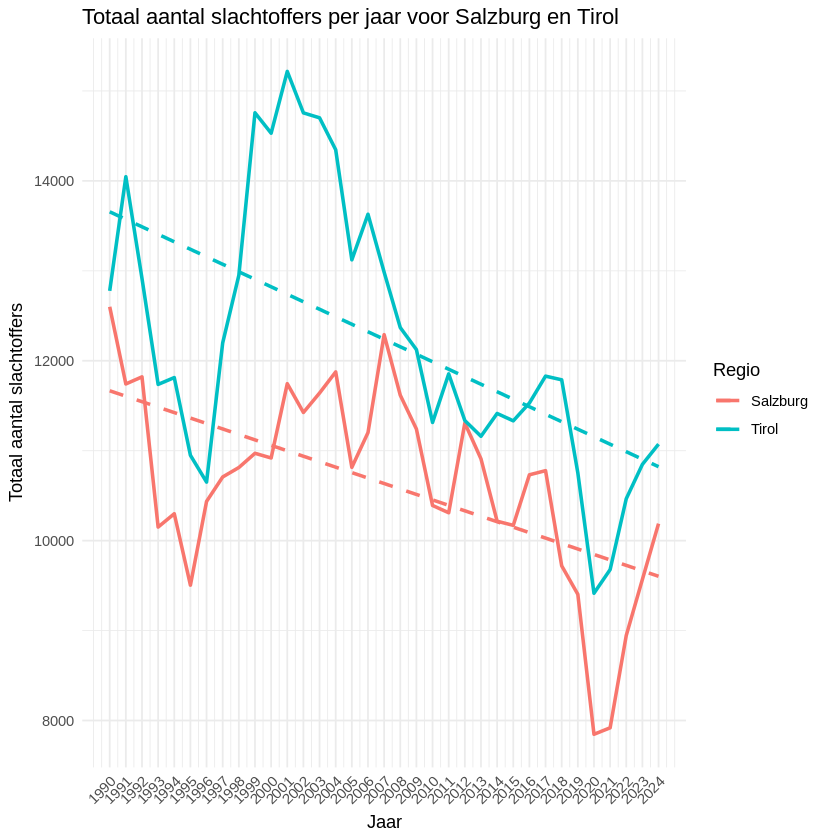

In [ ]:
data_filtered_regions <- data %>%
  filter(geo %in% c("AT32", "AT33"))

# Label the geo column
data_filtered_regions_labeled <- label_eurostat(data_filtered_regions, "geo")

data_by_year_region <- as_tibble(data_filtered_regions_labeled) %>%
  # Extract the year part from TIME_PERIOD before converting to numeric
  mutate(Year = as.numeric(str_sub(TIME_PERIOD, 1, 4))) %>%
  # Now filter out NAs if any remain from conversion (e.g., if some TIME_PERIOD were not dates)
  filter(!is.na(Year)) %>%
  group_by(Year, geo) %>% # Group by Year and the labeled geo
  summarise(total_victims = sum(values, na.rm = TRUE)) %>%
  ungroup()

data_by_year_region %>%
  ggplot(aes(x = Year, y = total_victims, color = geo)) + # Map geo to color
  geom_line(linewidth = 1) +
  geom_smooth(method = "lm", se = FALSE, linetype = "dashed") +
  labs(title = "Totaal aantal slachtoffers per jaar voor Salzburg en Tirol", x = "Jaar", y = "Totaal aantal slachtoffers", color = "Regio") + # Add color legend title
  theme_minimal() +
  scale_x_continuous(breaks = unique(data_by_year_region$Year), labels = unique(data_by_year_region$Year)) + # Explicitly set x-axis breaks and labels
  theme(axis.text.x = element_text(angle = 45, hjust = 1)) # Rotate x-axis labels

## Andere dataset

### Analysing Fertility Rates

In [ ]:
# Search for fertility rate dataset
fertility_data_search <- search_eurostat("fertility rate")
print(fertility_data_search)

# Based on common Eurostat dataset IDs, 'demo_find' or 'tps00199' often relates to fertility. Let's try 'demo_find' first.
# If 'demo_find' doesn't work or isn't detailed enough, we can investigate 'tps00199' or other relevant IDs from the search results.

# A tibble: 4 × 9
  title        code  type  last.update.of.data last.table.structure…¹ data.start
  <chr>        <chr> <chr> <chr>               <chr>                  <chr>     
1 Assumptions… proj… data… 15.04.2026          15.04.2026             2025      
2 Assumptions… proj… data… 24.05.2023          03.01.2024             2022      
3 Assumptions… proj… data… 20.07.2020          03.01.2024             2019      
4 Assumptions… proj… data… 16.11.2020          10.01.2024             2019      
# ℹ abbreviated name: ¹​last.table.structure.change
# ℹ 3 more variables: data.end <chr>, values <dbl>, hierarchy <dbl>


In [ ]:
# Load the fertility rate dataset. 'demo_frate' is a common Eurostat ID for Total Fertility Rate.
fertility_data <- get_eurostat("demo_frate")
head(fertility_data)

Table demo_frate cached at /tmp/RtmpzjIjg0/eurostat/886659c54098d29c8d0267b900a4abaf.rds



freq,unit,age,agedef,geo,TIME_PERIOD,values
<chr>,<chr>,<chr>,<chr>,<chr>,<date>,<dbl>
A,NR,TOTAL,COMPLET,AD,2006-01-01,1.23598
A,NR,TOTAL,COMPLET,AD,2007-01-01,1.17811
A,NR,TOTAL,COMPLET,AD,2008-01-01,1.25228
A,NR,TOTAL,COMPLET,AD,2009-01-01,1.19414
A,NR,TOTAL,COMPLET,AD,2010-01-01,1.27491
A,NR,TOTAL,COMPLET,AL,2002-01-01,1.90345


In [ ]:
# Inspect the columns to understand the data structure
colnames(fertility_data)

[1] "freq"        "indic_de"    "geo"         "TIME_PERIOD" "values"

The `demo_frate` dataset appears to contain data on fertility rates. The `TIME_PERIOD` column likely contains the year. We will filter the data for the latest available year and visualize the fertility rate per country.

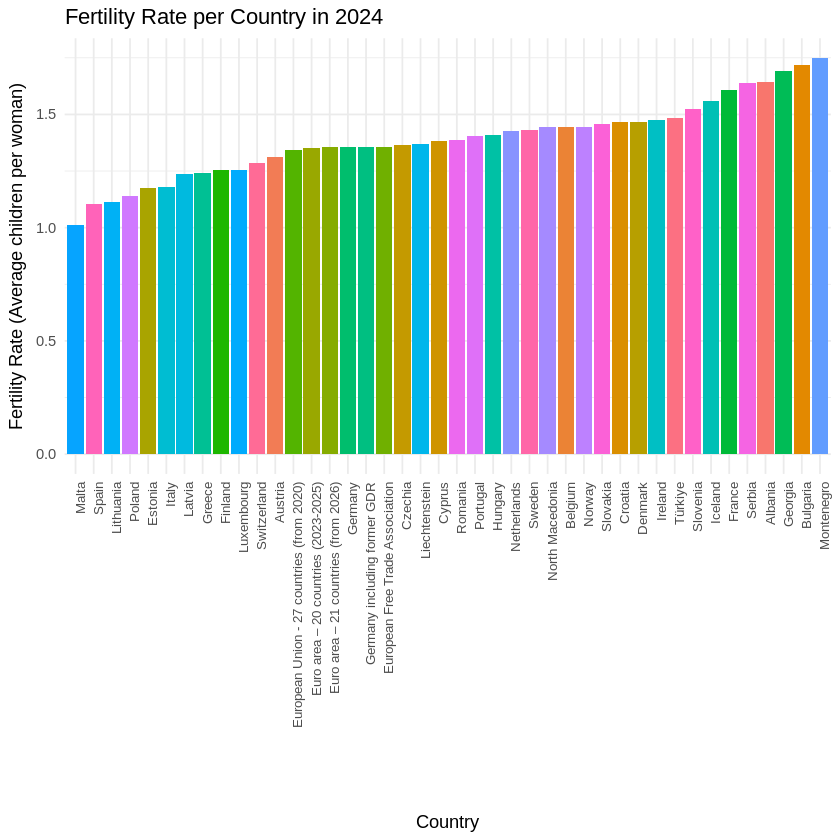

In [ ]:
# Clean and prepare the fertility data
fertility_data_cleaned <- fertility_data %>%
  # The 'demo_frate' dataset directly provides total fertility rate in 'values'
  # and often has 'age' == 'TOTAL' and 'agedef' == 'COMPLET' for this indicator.
  filter(age == "TOTAL", agedef == "COMPLET") %>%
  drop_na(values, geo, TIME_PERIOD) %>% # Ensure all necessary columns have values
  mutate(Year = as.numeric(format(TIME_PERIOD, "%Y"))) %>% # Create the Year column here
  select(-TIME_PERIOD) # Remove TIME_PERIOD after deriving Year

# Get the latest year available from TIME_PERIOD
latest_year <- max(fertility_data_cleaned$Year, na.rm = TRUE)

# Filter for the latest year and then label the 'geo' column
fertility_latest_year_labeled <- fertility_data_cleaned %>%
  filter(Year == latest_year) %>%
  select(geo, values) %>% # ONLY select geo and values for labeling step
  label_eurostat("geo") %>% # Label only the 'geo' column
  mutate(Year = latest_year) # Add the Year column back

# Create a bar chart for fertility rates in the latest year
fertility_latest_year_labeled %>%
  ggplot(aes(x = reorder(geo, values), y = values, fill = geo)) + # Reorder by values for better visualization
  geom_col(show.legend = FALSE) + # Hide legend as countries are on x-axis
  labs(title = paste("Fertility Rate per Country in", latest_year),
       x = "Country",
       y = "Fertility Rate (Average children per woman)") +
  theme_minimal() +
  theme(axis.text.x = element_text(angle = 90, hjust = 1, size = 8)) # Rotate x-axis labels

Now, let's identify the countries with the highest and lowest fertility rates.

In [ ]:
# Find the country with the highest fertility rate
max_fertility_country <- fertility_latest_year_labeled %>%
  arrange(desc(values)) %>%
  slice(1)

# Find the country with the lowest fertility rate
min_fertility_country <- fertility_latest_year_labeled %>%
  arrange(values) %>%
  slice(1)

cat("Country with the highest fertility rate in", latest_year, ":", max_fertility_country$geo, "(", max_fertility_country$values, ")\n")
cat("Country with the lowest fertility rate in", latest_year, ":", min_fertility_country$geo, "(", min_fertility_country$values, ")\n")

Country with the highest fertility rate in 2024 : Montenegro ( 1.74873 )
Country with the lowest fertility rate in 2024 : Malta ( 1.01304 )


### Trend van vruchtbaarheid over de laatste 10 jaar

`geom_smooth()` using formula = 'y ~ x'


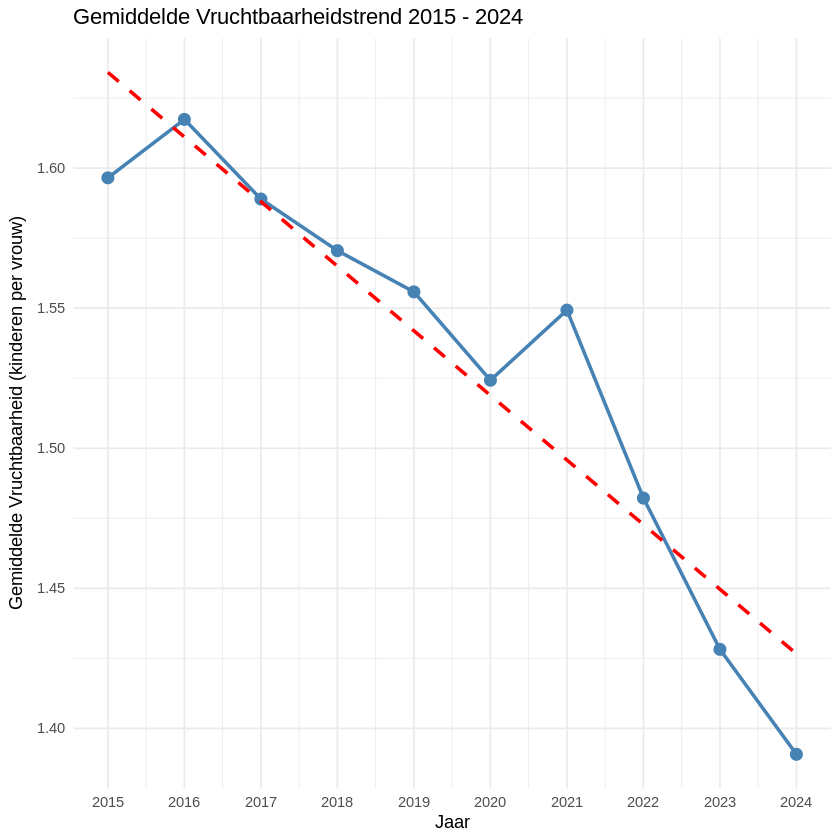

In [ ]:
# Calculate the start year for the last 10 years
start_year_for_trend <- latest_year - 9

# Filter data for the last 10 years
fertility_last_10_years <- fertility_data_cleaned %>%
  filter(Year >= start_year_for_trend) %>%
  # Calculate the average fertility rate per year across all geos
  group_by(Year) %>%
  summarise(average_fertility_rate = mean(values, na.rm = TRUE)) %>%
  ungroup()

# Create a line graph for the trend of average fertility rate
fertility_last_10_years %>%
  ggplot(aes(x = Year, y = average_fertility_rate)) +
  geom_line(color = "steelblue", linewidth = 1) +
  geom_point(color = "steelblue", size = 3) + # Add points for each year
  geom_smooth(method = "lm", se = FALSE, linetype = "dashed", color = "red") + # Add a linear trendline
  labs(title = paste("Gemiddelde Vruchtbaarheidstrend", start_year_for_trend, "-", latest_year),
       x = "Jaar",
       y = "Gemiddelde Vruchtbaarheid (kinderen per vrouw)") +
  theme_minimal() +
  scale_x_continuous(breaks = unique(fertility_last_10_years$Year)) # Ensure all years are shown on x-axis

### Vruchtbaarheid per Land (Kaart)

In [ ]:
install.packages(c("rnaturalearth", "sf", "countrycode"))

In [ ]:
library(rnaturalearth)
library(sf)
library(countrycode)

In [ ]:
# Get world map data
world_map <- ne_countries(scale = "medium", returnclass = "sf")

# Standardize country names in both datasets for merging
# Convert Eurostat geo codes to country names for better matching with world_map
fertility_latest_year_labeled_standardized <- fertility_latest_year_labeled %>%
  mutate(country = countrycode(geo, origin = "eurostat", destination = "country.name"))

# Merge fertility data with world map data
map_data <- world_map %>%
  left_join(fertility_latest_year_labeled_standardized, by = c("name_long" = "country"))

# Create the choropleth map
map_data %>%
  ggplot() +
  geom_sf(aes(fill = values), color = "white", linewidth = 0.1) +
  scale_fill_viridis_c(name = "Vruchtbaarheid") + # Use a color scale suitable for continuous data
  labs(title = paste("Vruchtbaarheid per Land in", latest_year),
       subtitle = "(Lichte gebieden hebben geen data)") +
  theme_minimal() +
  theme(axis.title.x = element_blank(), # Remove x-axis title
        axis.title.y = element_blank(), # Remove y-axis title
        panel.grid.major = element_blank(), # Remove major grid lines
        panel.grid.minor = element_blank(), # Remove minor grid lines
        legend.position = "bottom") # Position legend at the bottom

Installing packages into ‘/usr/local/lib/R/site-library’
(as ‘lib’ is unspecified)

also installing the dependencies ‘wk’, ‘terra’, ‘s2’, ‘units’


Warning message in install.packages(c("rnaturalearth", "sf", "countrycode")):
“installation of package ‘s2’ had non-zero exit status”
Warning message in install.packages(c("rnaturalearth", "sf", "countrycode")):
“installation of package ‘sf’ had non-zero exit status”
Warning message in install.packages(c("rnaturalearth", "sf", "countrycode")):
“installation of package ‘rnaturalearth’ had non-zero exit status”


ERROR: Error in library(rnaturalearth): there is no package called ‘rnaturalearth’
